In [5]:
# Import knihoven

import matplotlib.pyplot as plt # vykreslení grafů
import numpy as np # funkce, konstanty a pole
import pandas as pd # načtení dat

# $\text{Klasický 1 graf} $

In [6]:
# Načtení dat

data = pd.read_excel('ZA2_t06.xlsx') # načtení dat z excelu a uložení jako "data"
#print(data) # výpis dat...s čím pracujeme

hvezda = data['hvezda'] # pojmenování sloupce "hvezda" jako proměnné hvezda
M = data['M'] # pojmenování sloupce "M" jako proměnné M...odpovídající absolutní hvězdné velikosti
logP = data['logP'] # pojmenování sloupce "logP" jako proměnné logP...odpovídající logaritmu periody ve dnech

#print(hvezda) # výpis proměnné hvezda
data

,hvezda,M,logP
0,SU_Cas,-1.7,0.29
1,EV_Sct,-2.4,0.49
2,SS_Sct,-2.4,0.56
3,SU_Cyg,-2.8,0.58
4,Y_Lac,-2.8,0.64
5,FF_Aql,-3.1,0.65
6,CF_Cas,-3.4,0.69
7,V350_Sgr,-3.0,0.71
8,CV_Mon,-3.0,0.73
9,RR_Lac,-3.4,0.81


In [ ]:
# Defince přímky (výpoočet lineární regrese příště)

a=-3.51605 # koeficient a lineární regrese
b=-0.60081 # koeficient b lineární regrese

def lin(x): # definice lineární funkce
    return a*x+b

logP_value=np.linspace(np.min(logP), np.max(logP), 100) # vytvoření pole hodnot logP_value od min do max logP

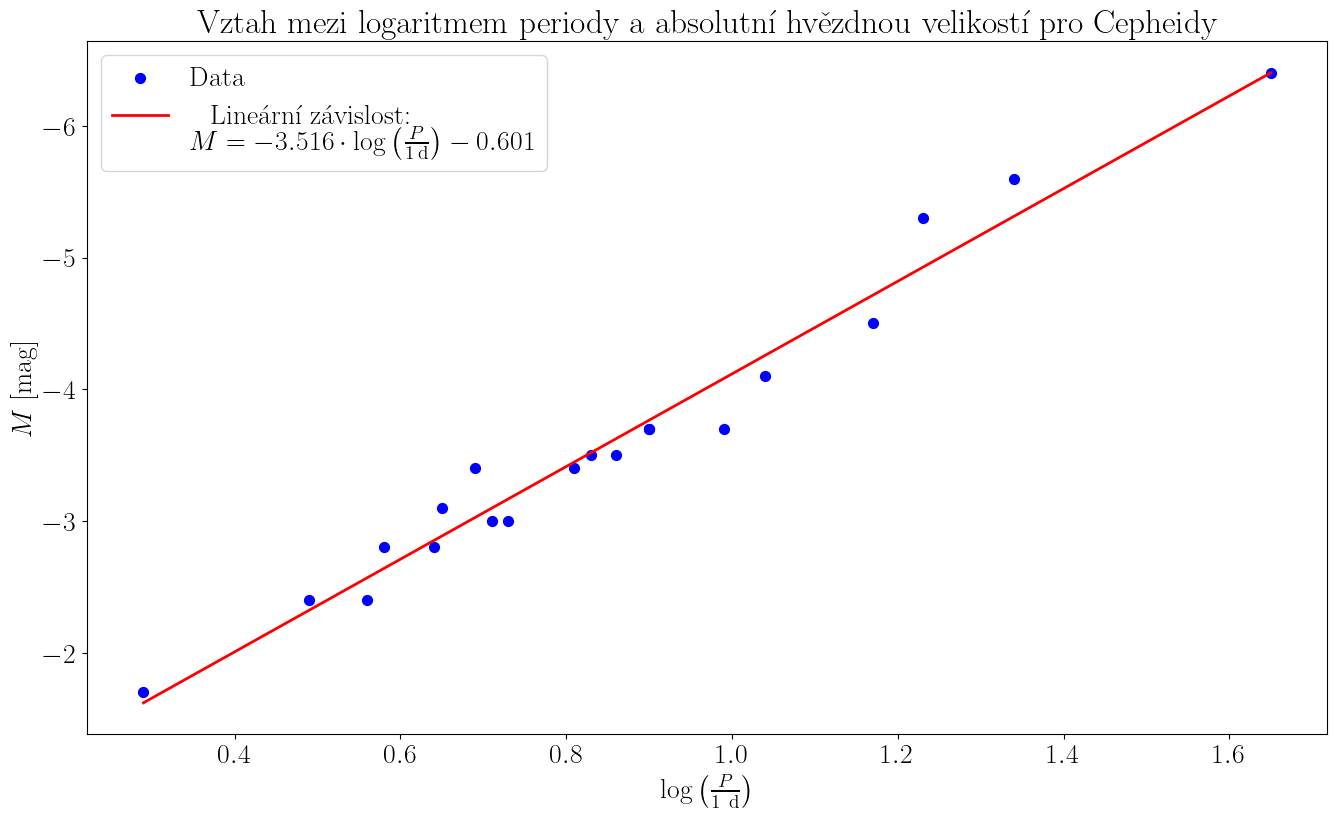

In [ ]:
#Ploting the data and the best fit line

# Nastavení pro správné zobrazení LaTeX fontu

plt.rc('font', size=20) # Nastavení velikosti fontu

# Latex font settings
plt.rcParams['text.usetex'] = True # povolení LaTeX fontu
plt.rcParams['font.family'] = 'serif' # nastavení serif fontu - fonty pro LaTeX fonty (Computer Modern, Times New Roman, Palatino, New Century Schoolbook, Bookman, Charter, Utopia)
plt.rcParams['font.serif'] = ['Computer Modern'] # Default serif font pro LaTeX


# Vytvoření grafu
fig, ax = plt.subplots(figsize=(16,9)) # rozměry grafu

plt.xlabel(r"$\log \left(\frac{P}{1\ \mathrm{d}}\right)$") # pojmenování osy x
plt.ylabel(r"$M$ [mag]") # pojmenování osy y
plt.gca().invert_yaxis() # obrácení osy y

plt.title(r"Vztah mezi logaritmem periody a absolutní hvězdnou velikostí pro Cepheidy") # pojmenování grafu (většinou se v literatuře moc nepoužívá)

plt.scatter(logP, M, color='blue', marker='o', s=50, label='Data') # vykreslení dat (x,y, barva, styl, velikost, pojmenování pro legendu)
plt.plot(logP_value, lin(logP_value), 
         color='red', linewidth=2, 
         label=r'Lineární závislost:\\ $M =%0.3f\cdot\log \left(\frac{{P}}{{1\,\mathrm{{d}}}}\right)%+0.3f$' % (a, b)) # vykreslení spojité přímky (x,y, barva, tloušťka, 
                                                                                                            # pojmenování pro legendu)

plt.legend() # vykreslení legendy (do argumetu lze zadat pozice umístění, například: loc='upper right', loc='lower left', loc='best'...nebo souřadnice x,y)
plt.show() # vykreslení grafu

fig.savefig('ZA2_t06_graf.png', bbox_inches='tight') # uložení grafu do obrázku + oříznutí okrajů (bbox_inches='tight')

# $\text{Více grafů} $

In [8]:
# Vytvoření dat - tuto buňku je možné igonrovat

lam_data = np.linspace(-10, 10, 100) # rozsah hodnot pro spektrální čáru
lam=np.linspace(-10, 10, 1000) # rozsah hodnot pro spektrální čáru (pro vykreslení spojité křivky)
A=0.0075 # nastavení síly šumu
G=0.25 # nastavení síly fyzikálního děje
r=4/3 # poměr apmlitudy extra signálu k amplitudě šumu

#reálná data s šumem a signálem
def rel(x):
    return 1-G/(1+x**2)+np.random.uniform(-A, A, size=len(lam_data))+(A*r)*np.sin(x) # fyzikální děj + šum + další signál (přístroj/experimentální chyba)

# funkce popisující reálný děj
def fit_fun(x):
    return 1-G/(1+x**2)

# funkce popisující další signál
def signal(x):
    return (A*r)*np.sin(x)

time_data=np.linspace(0, 10, 100) # rozsah hodnot pro vývoj spektrální čáry v čase
time=np.linspace(0, 10, 1000) # rozsah hodnot pro vývoj spektrální čáry v čase (pro vykreslení spojité křivky)

# zašuměná data
def noised(x):
    B=0.05
    return np.exp(-x)+np.random.uniform(-B, B, size=len(time_data))

# vývoj spektrální čáry v čase
def exp_fun(x):
    return np.exp(-x)

# tvorba dat a reziduí
rel_val=rel(lam_data) # reálná naměřená data (šum i extra signál)
fit_val=fit_fun(lam_data) # fyzikální děj (fit)
res=rel_val-fit_val # rezidua dat (rozdíl mezi reálnými daty a fit)

res_noised=noised(time_data)-exp_fun(time_data) # rezidua dat (rozdíl mezi reálnými daty a fit)
df = pd.DataFrame({'lam_data': lam_data, 'rel_val': rel_val, 'fit_val': fit_val, 'res': res}) # vytvoření datového rámce (dataframe) pro reálná data
df.to_csv('Spectra.csv', index=False) # uložení datového rámce do csv souboru (bez indexu)

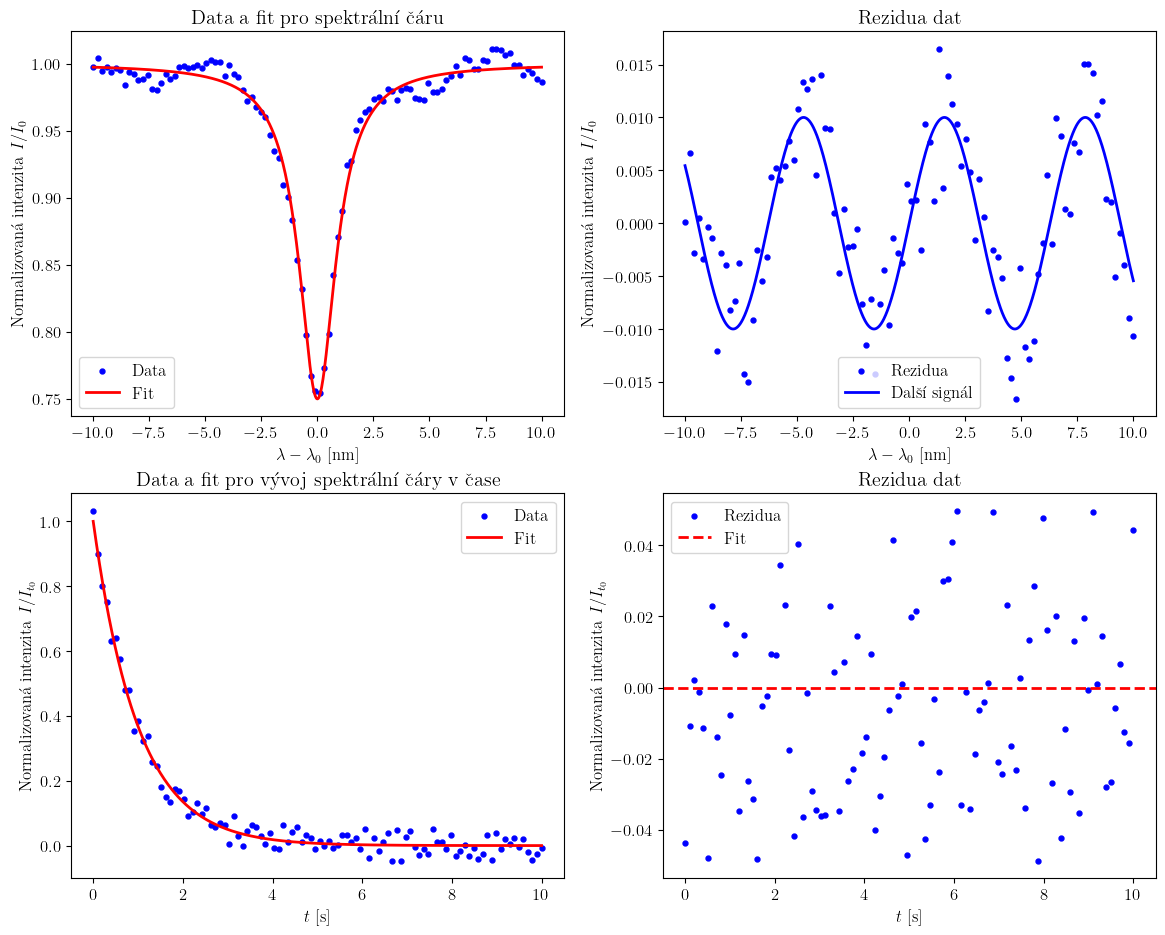

In [ ]:
# Hlavní část kódu pro vykreslení grafů

plt.rc('font', size=12)
plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Computer Modern'] # po sem už známe
fig, axs = plt.subplots(2, 2, figsize=(14, 11)) # vykreslení 4 grafů (2x2) + nastavení velikosti grafu

# Levý horní - první várka dat
axs[0,0].set_xlabel(r"$\lambda-\lambda_0$ [nm]")
axs[0,0].set_ylabel(r"Normalizovaná intenzita $I/I_0$")
axs[0,0].set_title(r"Data a fit pro spektrální čáru")
axs[0,0].scatter(lam_data, rel_val, color='blue', marker='.', s=50, label='Data')
axs[0,0].plot(lam, fit_fun(lam), color='red', linewidth=2, label='Fit')
axs[0,0].legend()

# Pravý horní - rezidua

axs[0,1].set_xlabel(r"$\lambda-\lambda_0$ [nm] ")
axs[0,1].set_ylabel(r"Normalizovaná intenzita $I/I_0$")
axs[0,1].set_title(r"Rezidua dat")
axs[0,1].scatter(lam_data, res, color='blue', marker='.', s=50, label='Rezidua')
axs[0,1].plot(lam, signal(lam), color='blue', linewidth=2, label='Další signál')
axs[0,1].legend()

# Levý dolní - druhá várka dat
axs[1,0].set_xlabel(r"$t$ [s]")
axs[1,0].set_ylabel(r"Normalizovaná intenzita $I/I_{t_0}$")
axs[1,0].set_title(r"Data a fit pro vývoj spektrální čáry v čase")
axs[1,0].scatter(time_data, noised(time_data), color='blue', marker='.', s=50, label='Data')
axs[1,0].plot(time, exp_fun(time), color='red', linewidth=2, label='Fit')
axs[1,0].legend()

# Pravý dolní - rezidua
axs[1,1].set_xlabel(r"$t$ [s]")
axs[1,1].set_ylabel(r"Normalizovaná intenzita $I/I_{t_0}$")
axs[1,1].set_title(r"Rezidua dat")
axs[1,1].scatter(time_data, res_noised, color='blue', marker='.', s=50, label='Rezidua')
axs[1,1].axhline(0, color='red', linestyle='--', linewidth=2, label='Fit')
axs[1,1].legend()

plt.show()


# $\text{Úkol:}$
$\text{Vytvořte graf pro funkci}$
$$y=\arctan(x) $$
$\text{a vykreslete ji do grafu.} $